# Libreta de Análisis de Datos de Accidentes de Tráfico en México

Esta libreta tiene como objetivo analizar los datos de accidentes de tráfico en México, explorando patrones y tendencias relevantes.

Se utilizarán técnicas de análisis exploratorio de datos (EDA) para obtener información sobre la frecuencia, ubicación y características de los accidentes, así como para identificar relación entre el estado de las calles y la ocurrencia de accidentes.

## Importación de Librerías

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Importación de Datos

Los datos no se encuentran guardados directamente en este proyecto. Es necesario correr primero el script para descargar los datos primero antes de correr esta libreta. Si no lo has hecho puedes correr el siguiente comando para descargar los datos

```bash
make data
```

In [3]:
from pathlib import Path

DATASET_PATH = Path.cwd().parent / "data" / "raw" / "traffic_accidents_mx.xlsx"
accidents_data = pd.read_excel(DATASET_PATH, sheet_name="Sheet 1 - atus_tr_cifra_2015")
accidents_data.head()

,COBERTURA,ID_ENTIDAD,ID_MUNICIPIO,ANIO,MES,ID_HORA,ID_MINUTO,ID_DIA,DIASEMANA,URBANA,...,PEATMUERTO,PEATHERIDO,CICLMUERTO,CICLHERIDO,OTROMUERTO,OTROHERIDO,NEMUERTO,NEHERIDO,CLASACC,ESTATUS
0,Municipal,1,1,2015,Enero,20,40,27,Martes,Accidente en no intersección,...,0,0,0,0,0,0,0,0,Sólo Daños,Cifras definitivas
1,Municipal,1,1,2015,Enero,0,0,1,Jueves,Accidente en no intersección,...,0,0,0,0,0,0,0,0,Sólo Daños,Cifras definitivas
2,Municipal,1,1,2015,Enero,17,0,28,Miércoles,Accidente en intersección,...,0,0,0,0,0,0,0,0,No fatal,Cifras definitivas
3,Municipal,1,1,2015,Enero,8,40,1,Jueves,Accidente en no intersección,...,0,0,0,0,0,0,0,0,Sólo Daños,Cifras definitivas
4,Municipal,1,1,2015,Enero,23,40,30,Viernes,Accidente en intersección,...,0,0,0,0,0,0,0,0,Sólo Daños,Cifras definitivas


In [4]:
# Shape and basic info
print("Dimensiones:", accidents_data.shape)

# Check missing values in critical columns
critical_cols = ['CAPAROD', 'SUBURBANA', 'TIPACCID', 'CLASACC', 'CAUSAACCI']
missing_info = accidents_data[critical_cols].isnull().sum()
print("\nValores nulos en columnas críticas:")
print(missing_info)

# Check data types
print("\nTipos de datos de columnas críticas:")
print(accidents_data[critical_cols].dtypes)

Dimensiones: (180066, 45)

Valores nulos en columnas críticas:
CAPAROD      0
SUBURBANA    0
TIPACCID     0
CLASACC      0
CAUSAACCI    0
dtype: int64

Tipos de datos de columnas críticas:
CAPAROD      str
SUBURBANA    str
TIPACCID     str
CLASACC      str
CAUSAACCI    str
dtype: object


¿Qué tipo de choques hay en calles no pavimentadas?

BUSQUEDA: ¿Predominan las salidas de camino, los choques contra objetos fijos, o volcaduras en las calles de terracería/no pavimentadas en comparación con las pavimentadas? Esto le dirá al municipio qué elementos de seguridad vial (como señalamientos o letreros) faltan en zonas sin pavimentar.

In [5]:
# Filtro de superficie
df_no_pavimentada = accidents_data[accidents_data['CAPAROD'] == "No Pavimentada"]

# Distribucion de frecuencia 
conteo_tipos = df_no_pavimentada['TIPACCID'].value_counts()
porcentaje_tipos = df_no_pavimentada['TIPACCID'].value_counts(normalize=True) * 100

# Combinamos ambos resultados
tabla_combinada = pd.DataFrame({
    'Conteo': conteo_tipos,
    'Porcentaje (%)': porcentaje_tipos.round(2)
})

# 4. Mostramos la tabla resultante
print(tabla_combinada)

                                       Conteo  Porcentaje (%)
TIPACCID                                                     
Colisión con vehículo automotor          1097           46.00
Colisión con objeto fijo                  430           18.03
Volcadura                                 247           10.36
Colisión con motocicleta                  150            6.29
Colisión con peatón (atropellamiento)     129            5.41
Salida del camino                         118            4.95
Colisión con ciclista                      79            3.31
Otro                                       42            1.76
Caída de pasajero                          35            1.47
Colisión con animal                        31            1.30
Incendio                                   14            0.59
Colisión con ferrocarril                   13            0.55


¿Qué porcentaje de calles no pavimentadas ocurre específicamente en un entorno suburbano frente al urbano?

In [6]:
# Tabla cruzada de frecuencias absolutas con totales marginales
crosstab_zona = pd.crosstab(accidents_data['CAPAROD'], accidents_data['SUBURBANA'], margins=True)
print(crosstab_zona)

SUBURBANA       Accidente en camino rural  Accidente en carretera estatal  \
CAPAROD                                                                     
No Pavimentada                        385                             128   
Pavimentada                          1492                            7408   
All                                  1877                            7536   

SUBURBANA       Accidentes en otro camino  Sin accidente en esta zona     All  
CAPAROD                                                                        
No Pavimentada                        119                        1753    2385  
Pavimentada                           959                      167822  177681  
All                                  1078                      169575  180066  


¿La gravedad de los choques es menor en una calle no pavimentada porque se maneja más lento?

In [7]:
# Tabla cruzada porcentual por fila para comparar la gravedad
crosstab_gravedad = pd.crosstab(accidents_data['CAPAROD'], accidents_data['CLASACC'], normalize='index') * 100

# Mostramos redondeado a dos decimales
print(crosstab_gravedad.round(2))

CLASACC         Fatal  No fatal  Sólo Daños
CAPAROD                                    
No Pavimentada   2.85     23.27       73.88
Pavimentada      0.97     20.19       78.84


¿Qué tipo de vehículos tienden a tener más accidentes? ¿En qué tipo de calles suburbanas?

BUSQUEDA: ¿Son las motocicletas o las camionetas las que más sufren incidentes en caminos rurales o suburbanos no pavimentados? Esto ayuda a los municipios a priorizar qué tipo de tráfico vehicular necesita mejor infraestructura en las periferias.

In [8]:
zona_suburbana = accidents_data[accidents_data['SUBURBANA'] != 'Sin accidente en esta zona']

cols_vehiculo = ['AUTOMOVIL', 'CAMPASAJ', 'MICROBUS', 'PASCAMION', 'OMNIBUS', 
                'TRANVIA', 'CAMIONETA', 'CAMION', 'TRACTOR', 'FERROCARRI', 
                'MOTOCICLET', 'BICICLETA', 'OTROVEHIC']

# Agrupamos por tipo de zona suburbana y vehiculos involucrados
vehiculos_por_zona_suburbana = zona_suburbana.groupby('SUBURBANA')[cols_vehiculo].sum()

print("Vehículos involucrados por tipo de zona suburbana")
print(vehiculos_por_zona_suburbana)


Vehículos involucrados por tipo de zona suburbana
                                AUTOMOVIL  CAMPASAJ  MICROBUS  PASCAMION  \
SUBURBANA                                                                  
Accidente en camino rural            1499       401         2         32   
Accidente en carretera estatal       5999      1919        38        132   
Accidentes en otro camino             969       203         3         25   

                                OMNIBUS  TRANVIA  CAMIONETA  CAMION  TRACTOR  \
SUBURBANA                                                                      
Accidente en camino rural            15        0        416      91       53   
Accidente en carretera estatal       44        1       1772     647      335   
Accidentes en otro camino             7        0        191     105       30   

                                FERROCARRI  MOTOCICLET  BICICLETA  OTROVEHIC  
SUBURBANA                                                                     
Accidente 

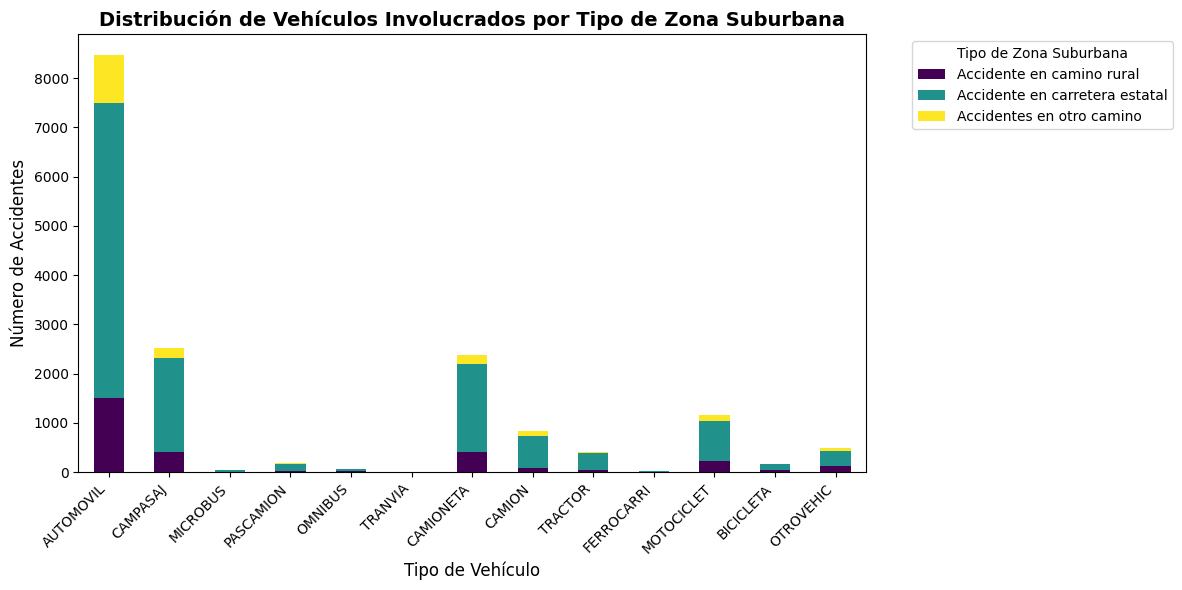

In [9]:
# Transponemos la tabla 
plot_data = vehiculos_por_zona_suburbana.T

ax = plot_data.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='viridis')

plt.title('Distribución de Vehículos Involucrados por Tipo de Zona Suburbana', fontsize=14, fontweight='bold')
plt.xlabel('Tipo de Vehículo', fontsize=12)
plt.ylabel('Número de Accidentes', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Tipo de Zona Suburbana', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

plt.show()

¿La gravedad de los choques es menor en una calle no pavimentada?

HIPOTESIS: al haber terracería se maneja más lento y hay menos fatalidades. la falta de señalamientos, baches profundos o la combinación con falta de iluminación provoca accidentes igual o más graves a menor velocidad.

In [10]:
# Tabla de porcentajes 
gravedad_porcentaje = pd.crosstab(accidents_data['CAPAROD'], accidents_data['CLASACC'], normalize='index') * 100
print(gravedad_porcentaje.round(2))

print("---")
# Tabla de conteos absolutos para ver el volumen real
gravedad_absoluta = pd.crosstab(accidents_data['CAPAROD'], accidents_data['CLASACC'])
print(gravedad_absoluta)

CLASACC         Fatal  No fatal  Sólo Daños
CAPAROD                                    
No Pavimentada   2.85     23.27       73.88
Pavimentada      0.97     20.19       78.84
---
CLASACC         Fatal  No fatal  Sólo Daños
CAPAROD                                    
No Pavimentada     68       555        1762
Pavimentada      1729     35877      140075


¿Hay diferencia entre calles no pavimentadas vs. pavimentadas, pero con mala condición de calle?

BUSQUEDA: ¿Un bache severo en una calle pavimentada genera un patrón de accidentes (por ejemplo, choque contra objeto fijo o pérdida control) similar al de una calle de tierra? Esto justifica económicamente ante el municipio si es mejor bachear o pavimentar por completo.

In [12]:
# Proporcion causas de accidentes por tipo de superficie
crosstab_causa = pd.crosstab(accidents_data['CAPAROD'], accidents_data['CAUSAACCI'], normalize='index') * 100

print(crosstab_causa.round(2))

CAUSAACCI       Conductor  Falla del vehículo  Mala condición del camino  \
CAPAROD                                                                    
No Pavimentada       89.9                2.98                       2.10   
Pavimentada          95.8                0.65                       1.35   

CAUSAACCI       Otra  Peatón o pasajero  
CAPAROD                                  
No Pavimentada  3.06               1.97  
Pavimentada     1.40               0.80  
